In [143]:
import importlib

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sko.GA import RCGA, GA

from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PM
from pymoo.operators.sampling.rnd import FloatRandomSampling
from pymoo.indicators.hv import HV

import help
import hp_search


importlib.reload(help)
importlib.reload(hp_search)

<module 'hp_search' from 'c:\\Users\\mateu\\OneDrive\\Área de Trabalho\\Trabalho-Computacao-Natural---Otimiza-o-MOO\\hp_search.py'>

In [115]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.expand_frame_repr', False)

In [116]:
def plot_compromisso(
    solucoes,
    nomes_funcoes=None,
    titulo="Compromisso entre funções objetivo",
    escalas=None
):
    """
    Gera um radar chart para um número arbitrário de funções objetivo.

    Parameters
    ----------
    solucoes : array ou dict
        Matriz (n_solucoes, n_objetivos) ou dicionário
        {nome_solucao: residuos}.

    nomes_funcoes : list, optional
        Nomes das funções objetivo.

    titulo : str
        Título do gráfico.

    escalas : array, optional
        Escalas de normalização, uma para cada objetivo.

    Notes
    -----
    A solução minimax é selecionada considerando o menor
    máximo resíduo normalizado.
    """

    # Interpretação das soluções
    if isinstance(solucoes, dict):
        nomes = list(solucoes.keys())
        valores = np.array(list(solucoes.values()), dtype=float)
    else:
        valores = np.asarray(solucoes, dtype=float)

        if valores.ndim == 1:
            valores = valores.reshape(1, -1)

        nomes = [f"Solução {i+1}" for i in range(len(valores))]

    # Validações
    if valores.ndim != 2 or valores.shape[0] == 0 or valores.shape[1] == 0:
        raise ValueError("solucoes deve ser uma matriz não vazia.")

    if not np.all(np.isfinite(valores)):
        raise ValueError("As soluções devem conter apenas valores finitos.")

    n_solucoes, n_funcoes = valores.shape


    idx_best = np.argmin([np.linalg.norm(valor) for valor in valores])

    # Nomes das funções
    if nomes_funcoes is None:
        nomes_funcoes = [f"f{i+1}" for i in range(n_funcoes)]

    if len(nomes_funcoes) != n_funcoes:
        raise ValueError(
            f"Informe exatamente {n_funcoes} nomes de funções."
        )

    # Construção dos ângulos
    angulos = np.linspace(
        0, 2 * np.pi, n_funcoes, endpoint=False
    )
    angulos_fechados = np.append(angulos, angulos[0])

    fig, ax = plt.subplots(
        figsize=(max(8, n_funcoes), max(8, n_funcoes)),
        subplot_kw={"polar": True}
    )

    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_xticks(angulos)
    ax.set_xticklabels(nomes_funcoes)

    # Demais soluções em cinza
    for i, residuos in enumerate(valores):
        if i == idx_best:
            continue

        dados = np.append(residuos, residuos[0])

        ax.plot(
            angulos_fechados,
            dados,
            color="gray",
            alpha=0.35,
            linewidth=1
        )

    # Solução minimax destacada
    melhor = valores[idx_best]
    dados_best = np.append(melhor, melhor[0])

    ax.plot(
        angulos_fechados,
        dados_best,
        color="red",
        linewidth=2.5,
        label=f"{nomes[idx_best]} (Menor norma l2)"
    )

    ax.fill(
        angulos_fechados,
        dados_best,
        color="red",
        alpha=0.12
    )

    maior = np.max(valores)
    ax.set_ylim(0, maior * 1.15 if maior > 0 else 1)

    ax.set_title(titulo, pad=25)
    ax.legend(loc="upper left", bbox_to_anchor=(1.05, 1.1))

    plt.tight_layout()
    plt.show()

<h3> Definição das funções dos problemas 1 e 2 e seus respectivos bounds

In [117]:
fun_1 = [
    lambda x: 0.8*(x[0]**2 + x[0] -  1)*x[2] + 0.12*x[0] + 2.16*x[0] - 0.12,
    lambda x: (1 + x[0]**2)*x[3] + 0.4*x[0]**2 - 1.6*x[0] - 0.4,
    lambda x: (1 + x[0]**2)*x[4] + x[0]**2 - 1,
    lambda x: (1 + x[0]**2)*x[5] + 0.8*(x[0]**2 + x[0] - 1),
    lambda x: x[2]*x[6] - 0.02*x[5] - x[4] - x[2]*x[3] - 0.16*x[3],
    lambda x: x[6]**2 - 2*x[3]*x[6] + x[5]**2 + x[3]**2 - x[1]**2,
    lambda x: x[7] - x[1]*x[2],
    lambda x: 0.0476*x[2]*x[7]**12 + x[2] - 2.104
]

fun_2 = [
    lambda x: x[4] + x[3] - 1.803,
    lambda x: (x[1] + x[2])*x[4] + 6.19116*x[3] - 1.803*(1.497 + 0.035),
    lambda x: x[5] + x[3] - 0.328,
    lambda x: 0.28801*x[5] - x[1]*x[2]*x[4],
    lambda x: (-6.19116*x[0] + x[0]*x[2] + x[1]*x[4] - x[2]*x[4])*x[5] + x[0]*x[2]*x[4],
    lambda x: 1.571*x[6] + x[3] - 1.803,
    lambda x: x[7] - 0.000856*x[6]**2,
    lambda x: (x[4] - x[0])*x[8] - x[0]*x[4],
    lambda x: x[8] - 377*x[1]*x[7]
]


In [118]:
lb_1 = [-3, -1, -2, -1, -1, -0.5, -1.5, -1.5]
ub_1 = [1, 1, 2, 1, 1, 0.5, 1.5, 1.5]

lb_2 = [-0.5, -1, -1, -1, 1, -1, -1, 0, -1]
ub_2 = [0.5, 1, 1, 1, 2, 1, 1, 1, 1]

In [ ]:
# hp_search.select_hp_grid(fun_1, lb_1, ub_1, 'rest_1.csv')

{'iters': 2000, 'size_pop': 50, 'prob_cros': 0.7, 'prob_mut': 0.01, 'mediana_cumprimentos': np.float64(4.0), 'mediana_fit': np.float64(0.54039851513899)}
{'iters': 2000, 'size_pop': 50, 'prob_cros': 0.7, 'prob_mut': 0.05, 'mediana_cumprimentos': np.float64(3.0), 'mediana_fit': np.float64(0.09309188459432)}
{'iters': 2000, 'size_pop': 50, 'prob_cros': 0.7, 'prob_mut': 0.1, 'mediana_cumprimentos': np.float64(0.0), 'mediana_fit': np.float64(0.10553830435940095)}
{'iters': 2000, 'size_pop': 50, 'prob_cros': 0.7, 'prob_mut': 0.2, 'mediana_cumprimentos': np.float64(0.0), 'mediana_fit': np.float64(0.2551644998359234)}
{'iters': 2000, 'size_pop': 50, 'prob_cros': 0.85, 'prob_mut': 0.01, 'mediana_cumprimentos': np.float64(4.0), 'mediana_fit': np.float64(0.4487252144592001)}
{'iters': 2000, 'size_pop': 50, 'prob_cros': 0.85, 'prob_mut': 0.05, 'mediana_cumprimentos': np.float64(3.0), 'mediana_fit': np.float64(0.18854431571665672)}
{'iters': 2000, 'size_pop': 50, 'prob_cros': 0.85, 'prob_mut': 0.1

In [ ]:
# hp_search.select_hp_grid(fun_2, lb_2, ub_2, 'rest_2.csv')

{'iters': 2000, 'size_pop': 50, 'prob_cros': 0.7, 'prob_mut': 0.01, 'mediana_cumprimentos': np.float64(6.0), 'mediana_fit': np.float64(0.12925552631813086)}
{'iters': 2000, 'size_pop': 50, 'prob_cros': 0.7, 'prob_mut': 0.05, 'mediana_cumprimentos': np.float64(6.0), 'mediana_fit': np.float64(0.02833947701225872)}
{'iters': 2000, 'size_pop': 50, 'prob_cros': 0.7, 'prob_mut': 0.1, 'mediana_cumprimentos': np.float64(0.0), 'mediana_fit': np.float64(0.10892099611943397)}
{'iters': 2000, 'size_pop': 50, 'prob_cros': 0.7, 'prob_mut': 0.2, 'mediana_cumprimentos': np.float64(0.0), 'mediana_fit': np.float64(0.3963373748889829)}
{'iters': 2000, 'size_pop': 50, 'prob_cros': 0.85, 'prob_mut': 0.01, 'mediana_cumprimentos': np.float64(6.0), 'mediana_fit': np.float64(0.07092751147176751)}
{'iters': 2000, 'size_pop': 50, 'prob_cros': 0.85, 'prob_mut': 0.05, 'mediana_cumprimentos': np.float64(7.0), 'mediana_fit': np.float64(0.02056896151395004)}
{'iters': 2000, 'size_pop': 50, 'prob_cros': 0.85, 'prob_mu

<h1> EXPERIMENTOS

<h4> FORMULAÇÃO COM RESTRIÇÕES

In [127]:
def executar_experimento_restricao(fun, lb, ub, execs, hp_config_file):
    hp_config = pd.read_csv(hp_config_file, sep=',')

    hp_config = hp_config.sort_values(['mediana_cumprimentos', 'mediana_fit'], ascending=[False, True])

    iters, size_pop, prob_cros, prob_mut = hp_config.head(1)[['iters', 'size_pop', 'prob_cros', 'prob_mut']].values[0]

    print(f"\nDentre os sets de hiperparâmetros testados, os melhores resultados foram obtidos por: \nIterações: {iters} \nTamanho da população: {size_pop} \nProbabilidade de Crossover: {prob_cros} \nProbabilidade de Mutação: {prob_mut}")

    dps, _ = help.get_media_dp(fun, lb, ub)
    def fun_obj(x):
        res = help.eval_fun(fun, x)
        res_normalizada = res/dps
        return np.sum(res_normalizada)

    resultados = []
    for i in range(execs):
        np.random.seed(i)
        
        ga = RCGA(
        func=fun_obj,
        n_dim=len(lb),
        size_pop=int(size_pop),
        max_iter=int(iters),
        prob_cros=prob_cros,
        prob_mut=prob_mut,
        lb=lb,
        ub=ub,
        )

        best_x, best_y = ga.run()

        res_dict = {}

        for k, x in enumerate(best_x):
           res_dict[f'x_{k+1}'] = x 

        for k, f in enumerate(help.eval_fun(fun, best_x)):
                   res_dict[f'f_{k+1}'] = f

        res_dict["fitness_normalizada"] = best_y[0]

        resultados.append(res_dict)

    df_res = pd.DataFrame(resultados).sort_values('fitness_normalizada')

    print("\n\nTabela sumarizando os 5 primeiros resultados (ordenados pela fitness)\n")
    print(df_res.head(5))

    print(f"\n\nPrincipais Estatísticas\n")
    print(df_res.describe())

    th = 1e-4
    restricoes_cumpridas = []
    residuos = []
    cols = [col for col in df_res.columns if col.split('_')[0] == 'f']
    for _, v in df_res.iterrows():
        restricoes_cumpridas.append(sum([1 for f in v[cols].values if f <= th]))
        residuos.append(sum([f for f in v[cols].values if f > th]))

    df_res['restricoes_cumpridas'] = restricoes_cumpridas
    df_res['residuos'] = residuos
    df_res = df_res.sort_values(['restricoes_cumpridas', 'residuos','fitness_normalizada'], ascending=[False, True, True])

    print(f"\n\nTabela indicando, por solução, quantas das restrições foram cumpridas, em que, uma vez que as restrições são igualdades, uma restrição é cumprida se for menor ou igual a {th}")
    print(df_res)


    print("\n\nAssim, temos a solução que mais cumpre as restrições (ou menos fere, de forma equivalente)\n")
    print(df_res.head(1))

    print("\n\nE a solução com a melhor fitness, que não necessariamente são iguais\n")
    print(df_res.sort_values('fitness_normalizada').head(1))

<h4> PROBLEMA 1

In [128]:
executar_experimento_restricao(fun_1, lb_1, ub_1, 30, 'rest_1.csv')


Dentre os sets de hiperparâmetros testados, os melhores resultados foram obtidos por: 
Iterações: 500.0 
Tamanho da população: 200.0 
Probabilidade de Crossover: 0.95 
Probabilidade de Mutação: 0.01


Tabela sumarizando os 5 primeiros resultados (ordenados pela fitness)

         x_1       x_2       x_3       x_4       x_5       x_6       x_7       x_8           f_1       f_2       f_3           f_4           f_5           f_6           f_7           f_8  fitness_normalizada
9   0.366058  0.624580  1.786729  0.881930  0.772506  0.352695  1.397212  1.115956  1.672620e-09  0.068014  0.010019  8.476298e-08  3.189035e-08  1.919161e-04  2.875103e-09  3.291266e-08             0.024170
27  0.378854 -0.537032  1.946392  0.851338  0.741290  0.334091  1.305602 -1.045266  8.527249e-05  0.024777  0.008783  4.976333e-05  1.071029e-05  2.956863e-02  8.695773e-06  7.658200e-06             0.036254
15  0.382855  0.495500  2.000000  0.828819  0.603038  0.328329  1.199927  0.991001  9.792706e-10  0.003

<h4> PROBLEMA 2

In [129]:
executar_experimento_restricao(fun_2, lb_2, ub_2, 30, 'rest_2.csv')


Dentre os sets de hiperparâmetros testados, os melhores resultados foram obtidos por: 
Iterações: 500.0 
Tamanho da população: 200.0 
Probabilidade de Crossover: 0.95 
Probabilidade de Mutação: 0.01


Tabela sumarizando os 5 primeiros resultados (ordenados pela fitness)

         x_1       x_2       x_3       x_4       x_5       x_6       x_7       x_8       x_9           f_1           f_2           f_3           f_4           f_5           f_6           f_7           f_8       f_9  fitness_normalizada
9  -0.116340 -0.520217  0.090028  0.534306  1.268694 -0.206306  0.807571  0.000558 -0.106568  0.000000e+00  7.993606e-15  1.665335e-16  1.387779e-17  6.817463e-16  0.000000e+00  3.014082e-17  9.714451e-16  0.002919             0.000035
8  -0.081786 -0.323853  0.110721  0.491307  1.311693 -0.163307  0.834941  0.000597 -0.076986  4.440892e-16  4.440892e-16  5.606626e-15  1.630640e-15  9.357098e-15  2.131628e-14  6.136584e-17  1.054712e-15  0.004128             0.000050
27 -0.056450 -0.169

<h4> FORMULAÇÃO MULTIOBJETIVO

In [150]:
def executar_experimento_moo(fun, lb, ub, execs, hp_config_file):
    hp_config = pd.read_csv(hp_config_file, sep=',')

    print("Variação dos hipervolumes (HV) em função dos hiperparâmetros")
    print(f'{hp_config['hipervolume'].mean()} +- {hp_config['hipervolume'].std()}')

    idx_max = hp_config['hipervolume'].argmax()
    n_gen, size_pop, prob_cros, prob_mut = hp_config.iloc[idx_max][['n_gen', 'size_pop', 'prob_cros', 'prob_mut']].values

    print(f"\nDentre os sets de hiperparâmetros testados, os melhores resultados foram obtidos por: \nNúmero de Gerações: {n_gen} \nTamanho da população: {size_pop} \nProbabilidade de Crossover: {prob_cros} \nProbabilidade de Mutação: {prob_mut}")

    class Problema(ElementwiseProblem):

            def __init__(self):
                super().__init__(
                    n_var=len(lb),      
                    n_obj=len(fun),      
                    xl=lb,
                    xu=ub
                )
            def _evaluate(self, x, out, *args, **kwargs):
                out["F"] = help.eval_fun(fun, x)

    problema = Problema()

    resultados = []

    for i in range(execs):
        algoritmo = NSGA2(
            pop_size=int(size_pop),
            sampling=FloatRandomSampling(),
            crossover=SBX(
                prob=prob_cros,
                eta=15),
            mutation=PM(
                prob=1.0,
                prob_var = prob_mut,
                eta=20),
            eliminate_duplicates=True)
            
        res = minimize(problema, algoritmo, termination=("n_gen", int(n_gen)), seed=i, verbose=False)

        res_dict = {
             "X": res.X,
             "F": res.F
        }
        resultados.append(res_dict)

    dps, _ = help.get_media_dp(fun, lb, ub)
    fronts = [resultado["F"] for resultado in resultados]
    fronts_norm = [front / dps for front in fronts]

    ref_point = hp_search.get_ref_point(fronts_norm)
    indicador_hv = HV(ref_point=ref_point)

    for resultado, front_norm in zip(resultados, fronts_norm):
        hv = indicador_hv.do(front_norm)
        resultado["hipervolume"] = hv

    df_res = pd.DataFrame(resultados)

    maior_hv_idx = np.argmax(df_res["hipervolume"])
    menor_hv_idx = np.argmin(df_res["hipervolume"])

    melhor_pareto = df_res.iloc[maior_hv_idx]   
    pior_pareto = df_res.iloc[menor_hv_idx]

    plot_compromisso(melhor_pareto['F']/dps, titulo="Melhor fronteira de acordo com o HV")
    plot_compromisso(pior_pareto['F']/dps, titulo="Pior fronteira de acordo com o HV")


    df_X = pd.DataFrame(
        melhor_pareto['X'],
        columns=[f'x_{i+1}' for i in range(len(melhor_pareto['X'][0]))])
    df_F = pd.DataFrame(
        melhor_pareto['F']/dps,
        columns=[f'f_{i+1}' for i in range(len(melhor_pareto['F'][0]))])

    df_stats = pd.concat([df_X, df_F], axis=1)

    df_stats['l2'] = [np.linalg.norm(sol/dps) for sol in df_stats[df_F.columns].values]

    print(df_stats.sort_values('l2').head(1))

    
    print(df_stats.describe())


<h4> PROBLEMA 1

Variação dos hipervolumes (HV) em função dos hiperparâmetros
197936705.50104472 +- 4674308.937015736

Dentre os sets de hiperparâmetros testados, os melhores resultados foram obtidos por: 
Número de Gerações: 2000.0 
Tamanho da população: 50.0 
Probabilidade de Crossover: 0.7 
Probabilidade de Mutação: 0.05


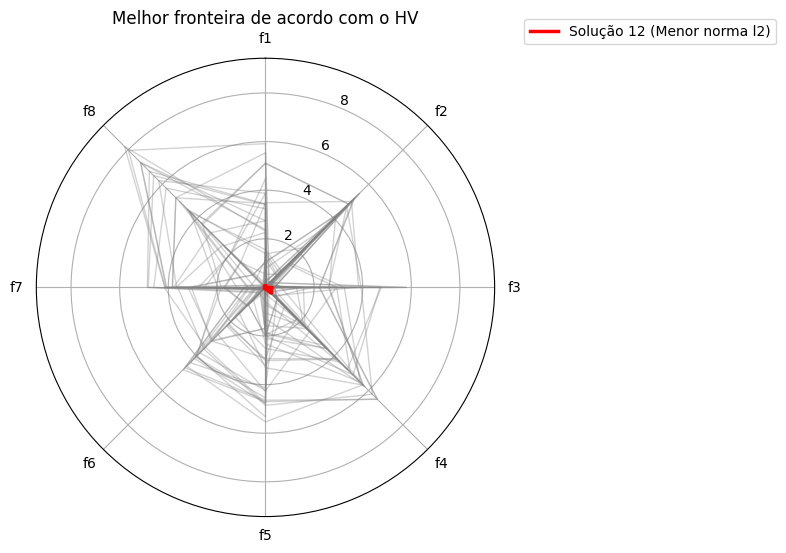

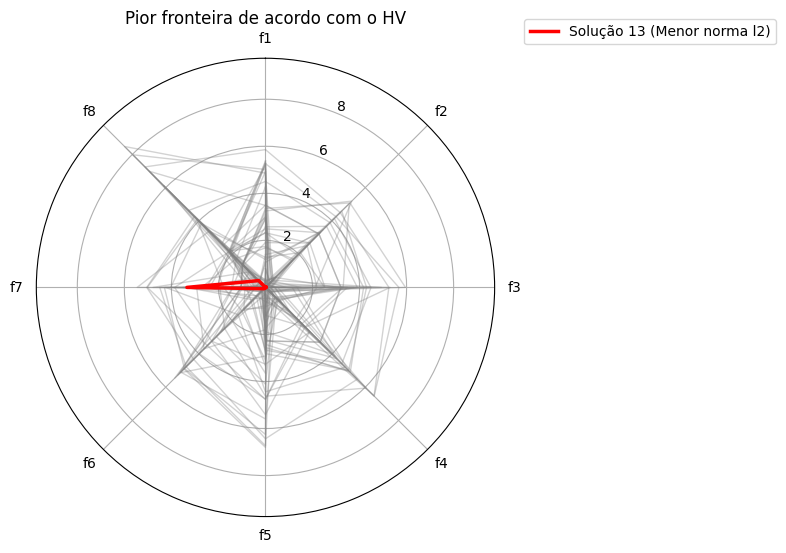

        x_1      x_2     x_3       x_4       x_5       x_6       x_7       x_8       f_1       f_2       f_3           f_4       f_5       f_6       f_7       f_8        l2
7 -2.993556  0.58346  1.7572 -0.905957 -0.681861 -0.398967 -1.329466  1.083581  0.015169  0.321712  0.390286  7.314381e-07  0.106342  0.001676  0.094219  0.070836  0.258872
             x_1        x_2        x_3        x_4        x_5        x_6        x_7        x_8           f_1           f_2           f_3           f_4           f_5           f_6           f_7           f_8         l2
count  50.000000  50.000000  50.000000  50.000000  50.000000  50.000000  50.000000  50.000000  5.000000e+01  5.000000e+01  5.000000e+01  5.000000e+01  5.000000e+01  5.000000e+01  5.000000e+01  5.000000e+01  50.000000
mean   -2.452791   0.524562   0.574655  -0.088394  -0.176561   0.115238  -0.976702   0.780085  1.580913e+00  1.750782e+00  1.289071e+00  2.180054e+00  1.969517e+00  1.412411e+00  1.673261e+00  2.208737e+00   5.678722
std

In [151]:
executar_experimento_moo(fun_1, lb_1, ub_1, 30, 'moo_1.csv')

<h4> PROBLEMA 2

Variação dos hipervolumes (HV) em função dos hiperparâmetros
7106031.745375921 +- 2341577.1933330307

Dentre os sets de hiperparâmetros testados, os melhores resultados foram obtidos por: 
Número de Gerações: 2000.0 
Tamanho da população: 50.0 
Probabilidade de Crossover: 0.7 
Probabilidade de Mutação: 0.1


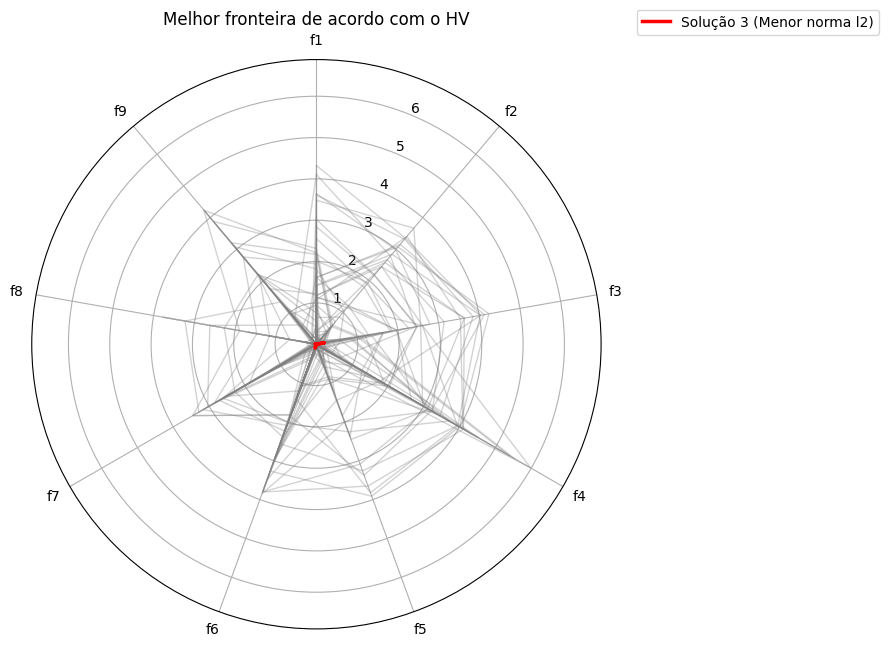

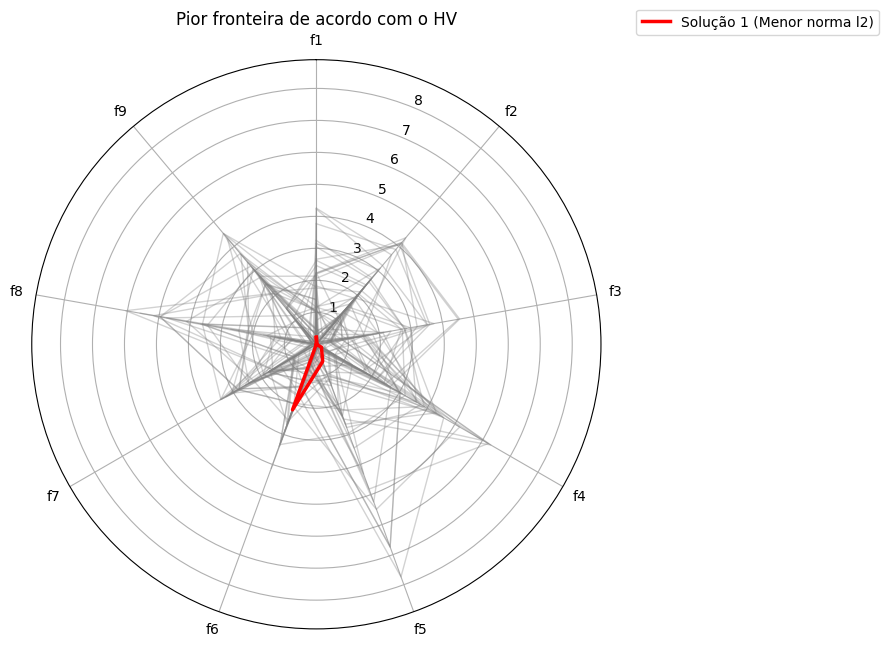

        x_1       x_2      x_3       x_4       x_5       x_6      x_7       x_8       x_9       f_1       f_2       f_3       f_4       f_5       f_6      f_7       f_8       f_9        l2
2 -0.178066 -0.869442  0.10217  0.598455  1.204543 -0.370908  0.70084  0.000415 -0.139604  0.000005  0.006937  0.196561  0.000507  0.011203  0.100108  0.00002  0.037567  0.000045  0.402232
             x_1        x_2        x_3        x_4        x_5        x_6        x_7        x_8        x_9        f_1           f_2        f_3        f_4           f_5           f_6           f_7           f_8           f_9         l2
count  50.000000  50.000000  50.000000  50.000000  50.000000  50.000000  50.000000  50.000000  50.000000  50.000000  5.000000e+01  50.000000  50.000000  5.000000e+01  5.000000e+01  5.000000e+01  5.000000e+01  5.000000e+01  50.000000
mean   -0.083341  -0.780463   0.143517   0.112050   1.415450  -0.513134   0.217781   0.269043   0.084143   1.381557  1.249770e+00   1.539503   1.914615  8.9

In [152]:
executar_experimento_moo(fun_2, lb_2, ub_2, 30, 'moo_2.csv')